# Evaluating Predictive Performance

It is important to understand how the performance of data mining and machine learning methods can be assessed. Building a model that fits the training data well is only the first step. If we rely only on training accuracy, we risk overfitting: creating a model that works perfectly on the data it has already seen, but performs poorly on new unseen data. To avoid this, we evaluate model performance on a validation or test set that was not used in training.

In this tutorial, we will use Python to explore several key performance metrics. For prediction (**regression**), we will look at the Average Error, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE), and R-squared. For **classification**, we will review the metrics derived from the confusion matrix such as accuracy, sensitivity (recall), and specificity. We will also study how the choice of cutoff values affects classification results. Python libraries such as scikit-learn allow us to generate ROC (Receiver Operating Characteristic) curves, which visualize model performance across different cutoffs.

When the goal is to rank records rather than classify the entire dataset (for example, identifying the top 10% of customers most likely to respond to an offer or the 5% of claims most likely to be fraudulent), we can use Lift chart to measure performance. 

## Regression 

In [1]:
import pandas as pd
import numpy as np

In [44]:
#Load the Toyota Corolla Dataset
car_df = pd.read_csv("ToyotaCorolla.csv")

#Explore the Toyota Corolla Dataset
print("First five rows:\n ", car_df.head())

print(car_df.info())

print(car_df.describe())

First five rows:
     Id                                          Model  Price  Age_08_04  \
0   1  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13500         23   
1   2  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13750         23   
2   3  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13950         24   
3   4  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  14950         26   
4   5    TOYOTA Corolla 2.0 D4D HATCHB SOL 2/3-Doors  13750         30   

   Mfg_Month  Mfg_Year     KM Fuel_Type  HP  Met_Color  ... Powered_Windows  \
0         10      2002  46986    Diesel  90          1  ...               1   
1         10      2002  72937    Diesel  90          1  ...               0   
2          9      2002  41711    Diesel  90          1  ...               0   
3          7      2002  48000    Diesel  90          0  ...               0   
4          3      2002  38500    Diesel  90          0  ...               1   

   Power_Steering  Radio  Mistlamps  Sport_Model  Backseat_Di

In [45]:
car_df.columns

Index(['Id', 'Model', 'Price', 'Age_08_04', 'Mfg_Month', 'Mfg_Year', 'KM',
       'Fuel_Type', 'HP', 'Met_Color', 'Color', 'Automatic', 'CC', 'Doors',
       'Cylinders', 'Gears', 'Quarterly_Tax', 'Weight', 'Mfr_Guarantee',
       'BOVAG_Guarantee', 'Guarantee_Period', 'ABS', 'Airbag_1', 'Airbag_2',
       'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player',
       'Central_Lock', 'Powered_Windows', 'Power_Steering', 'Radio',
       'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim',
       'Radio_cassette', 'Parking_Assistant', 'Tow_Bar'],
      dtype='object')

In [46]:
#Setting our list of variables (Excluding the output variables and text variables, Id)

categorical_var = car_df.select_dtypes(include=['object']).columns.tolist()

print(categorical_var)

['Model', 'Fuel_Type', 'Color']


In [8]:
#Define predictors: all columns except categorical vars and 'Id'
predictors = [col for col in car_df.columns 
              if col not in categorical_var + ['Id'] + ['Price']
             ]
#Define the outcome variable
outcome = 'Price'

print("Independent Variables are:\n", predictors)
print("Dependent Variable is:", outcome)

Independent Variables are:
 ['Age_08_04', 'Mfg_Month', 'Mfg_Year', 'KM', 'HP', 'Met_Color', 'Automatic', 'CC', 'Doors', 'Cylinders', 'Gears', 'Quarterly_Tax', 'Weight', 'Mfr_Guarantee', 'BOVAG_Guarantee', 'Guarantee_Period', 'ABS', 'Airbag_1', 'Airbag_2', 'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player', 'Central_Lock', 'Powered_Windows', 'Power_Steering', 'Radio', 'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim', 'Radio_cassette', 'Parking_Assistant', 'Tow_Bar']
Dependent Variable is: Price


In [9]:
from sklearn.model_selection import train_test_split
import statsmodels.formula.api as smf

#Partition the dataset into 70% Training and 30% Test

X = car_df[predictors]
y = car_df[outcome]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#Combine train_X and train_y back into one DataFrame
train_df = X_train.copy()
train_df['Price'] = y_train

#Train the linear regression model
model = smf.ols(
        formula="""Price ~ Age_08_04 + Mfg_Month + Mfg_Year + KM + HP + Met_Color + Automatic + CC + Doors +
                Cylinders + Gears + Quarterly_Tax + Weight + Mfr_Guarantee + BOVAG_Guarantee + Guarantee_Period +
                ABS + Airbag_1 + Airbag_2 + Airco + Automatic_airco + Boardcomputer + CD_Player + Central_Lock + 
                Powered_Windows + Power_Steering + Radio + Mistlamps + Sport_Model + Backseat_Divider + Metallic_Rim +
                Radio_cassette + Parking_Assistant + Tow_Bar""",
                data = train_df
                )
result = model.fit()  
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.906
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                     293.6
Date:                Tue, 06 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:20:37   Log-Likelihood:                -8460.4
No. Observations:                1005   AIC:                         1.699e+04
Df Residuals:                     972   BIC:                         1.715e+04
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -0.0088      0.00

### Model Output Interpretation

In this case, the dependent variable is "Price".

R-squared (0.906) indicates that 90.6% of the variance in  prices is explained by the model. This is a very strong indicator of model fit.

Adjusted R-squared (0.903) accounts for the number of predictors and provides a more conservative estimate of model performance. It is good when comparing models with different numbers of variables.

F-statistic (293.6) assesses the overall significance of the regression model.

The Prob (F-statistic) of 0.00 means we reject the null hypothesis that none of the predictors matter, showing the model is statistically significant and at least one predictor is related to car prices.

Coeffecients: Example: For each increase in 1 unit of manufacturing month, the price decreases by $108.

Standard Error of Parameters: It is a measure of how much the coefficient estimates would vary if the same model were estimated with different samples from the same population.

The t-statistics are calculated by dividing the coefficient by its standard error.

The p-values associated with these t-statistics indicate the probability of observing the estimated coefficient (or a more extreme value) if the null hypothesis were true. A p-value below a certain significance level (usually 0.05) suggests that the coefficient is statistically significant.

The confidence intervals give a range within which the true coefficient likely falls, with a certain level of confidence.

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

#Predictions on test set
y_pred = result.predict(X_test)

#Compute metrics

errors = y_test - y_pred

mean_error = np.mean(errors)
mae = mean_absolute_error(y_test, y_pred) #or, mae = np.mean(np.abs(errors))
mape = mean_absolute_percentage_error (y_test, y_pred) #or, mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
mse = mean_squared_error(y_test, y_pred) #or, mse = np.mean(errors ** 2)
rmse = np.sqrt(mse) #or, rmse = np.sqrt(np.mean(errors ** 2))
r2 = r2_score(y_test, y_pred)

print("Predictive Performance on Test Data:")
print(f"Mean Error: {mean_error: .2f}")
print(f"MAE:  {mae:.2f}")
print(f"MAPE: {mape: .2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2_Score: {r2:.3f}")

Predictive Performance on Test Data:
Mean Error: -92.70
MAE:  835.92
MAPE:  0.09
MSE:  1362692.84
RMSE: 1167.34
R2_Score: 0.902


MAE (Mean Absolute Error) gives the magnitude of the average absolute error (**Shmueli, Bruce, Gedeck & Patel, 2019**).

Mean Error is similar to MAE except that it retains the sign of the errors, so that negative errors cancel out positive errors of the same magnitude. It therefore gives an indication of whether the predictions are on average over- or underpredicting the outcome variable.

MAPE (Mean Absolute Percentage Error) gives a percentage score of how predictions deviate (on average) from the actual values.

RMSE is similar to the standard error of estimate in linear regression, except that it is computed on the validation/test data rather than on the training data. It has the same units as the outcome variable. It takes the square root of the average squared error.

If RMSE is bigger than MAE, it means that we have some large errors/outliers, since squaring emphasizes them.

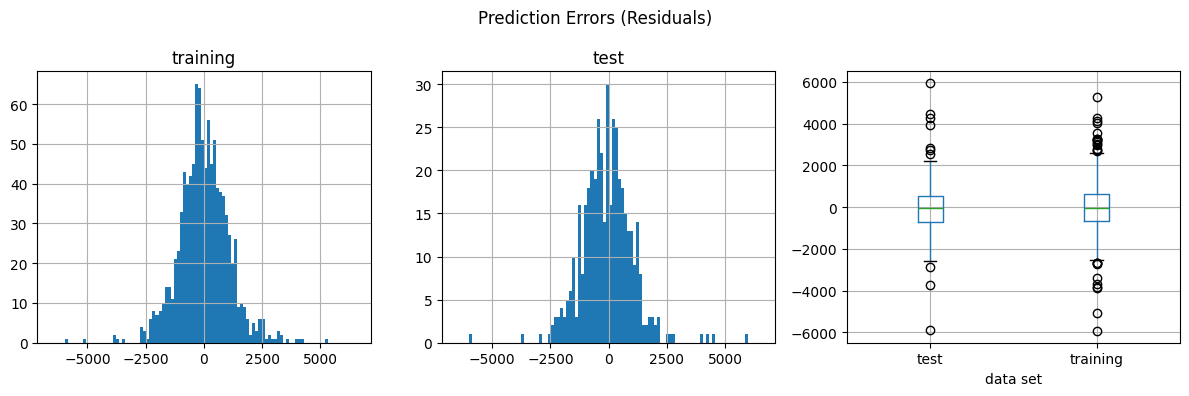

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Compute residuals (errors)
pred_error_train = pd.DataFrame({
    'residual': y_train - result.predict(X_train),
    'data set': 'training'
})

pred_error_test = pd.DataFrame({
    'residual': y_test - result.predict(X_test),
    'data set': 'test'
})

# Combine into one dataframe
boxdata_df = pd.concat([pred_error_train, pred_error_test], ignore_index=True)

# Plot
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

common = {'bins': 100, 'range': [-6500, 6500]}

# Training residuals histogram
pred_error_train['residual'].hist(ax=axes[0], **common)
axes[0].set_title('training')

# Test residuals histogram
pred_error_test['residual'].hist(ax=axes[1], **common)
axes[1].set_title('test')

# Boxplot of both
boxdata_df.boxplot(column='residual', by='data set', ax=axes[2])
axes[2].set_ylim(-6500, 6500)
axes[2].set_title('')

# Overall figure title
plt.suptitle('Prediction Errors (Residuals)')
plt.tight_layout()
plt.show()

"Errors that are based on the training set tell us about model fit, whereas those that
are based on the validation set (called “prediction errors”) measure the model’s
ability to predict new data (predictive performance). We expect training errors
to be smaller than the validation errors (because the model was fitted using the
training set), and the more complex the model, the greater the likelihood that
it will overfit the training data (indicated by a greater difference between the
training and validation errors). In an extreme case of overfitting, the training
errors would be zero (perfect fit of the model to the training data), and the
validation errors would be non-zero and non-negligible. For this reason, it is
important to compare the error plots and metrics (RMSE, MAE, etc.) of the
training and validation sets." (**Shmueli, Bruce, Gedeck & Patel, 2019**)

We can see that: 

Training residuals: Errors are centered around zero and mostly within -2500 and +2500. The model captures car prices well.

Test residuals: Distribution is almost same as the training set. This means that the model generalizes effectively to unseen data.

Boxplots: Both training and test sets have similar spread and outliers. This indicates stability of performance and no overfitting.

### Lift and Decile Charts for Predictive Error

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a DataFrame to compare actual vs predicted values      
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison_df.head(15))  # Display the first 15 rows of the comparison DataFrame

      Actual     Predicted
594    10800  10674.418916
754     9950   9337.269349
630     7500   9194.482189
1259    9250   8335.222978
903     9750   9080.603285
1175    9950   8044.905921
762     9895   9432.836251
1372    6750   8191.461634
259    13450  13220.704894
316    12950  13332.929651
705     9900  10092.465113
906     9750   9792.608393
274    13500  12246.608348
361    11500  12913.047527
743     8950   9794.771206


In [21]:
#Sort predicted values in descending order
sorted_df = comparison_df.sort_values('Predicted', ascending=False).reset_index(drop=True)
print(sorted_df.head(15))

    Actual     Predicted
0    31275  26803.280871
1    32500  26556.395852
2    24950  24045.974818
3    24990  23651.806260
4    20950  21886.133680
5    19950  21788.616650
6    21950  21582.631724
7    22500  21556.604575
8    22000  20837.757361
9    21950  20465.380900
10   20500  20336.090460
11   24500  20220.105682
12   19750  20135.922408
13   23950  20040.645065
14   12450  20008.532796


In [22]:
# cumulative sums
sorted_df['cum_actual'] = sorted_df['Actual'].cumsum()
sorted_df['cum_pred']   = sorted_df['Predicted'].cumsum()

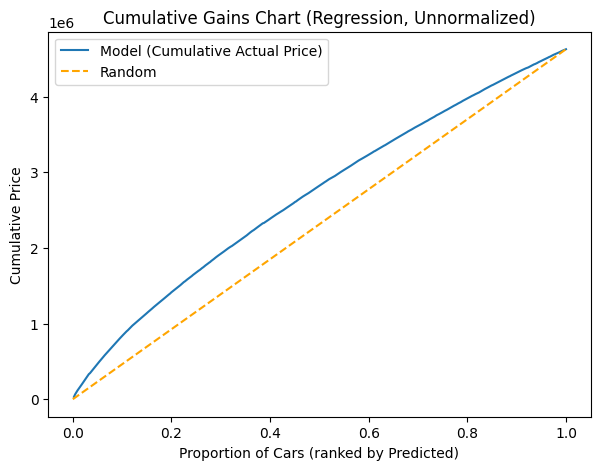

In [23]:
import numpy as np
import matplotlib.pyplot as plt

n = len(sorted_df)

# Proportion of records for the x-axis
sorted_df['cum_pct_records'] = np.arange(1, n+1) / n

# Plot cumulative actual price
plt.figure(figsize=(7,5))
plt.plot(sorted_df['cum_pct_records'], sorted_df['cum_actual'], 
         label='Model (Cumulative Actual Price)')

# Random baseline: straight line from 0 to total actual sum
plt.plot([0,1], [0, sorted_df['Actual'].sum()], linestyle='--', 
         color='orange', label='Random')

plt.xlabel('Proportion of Cars (ranked by Predicted)')
plt.ylabel('Cumulative Price')
plt.title('Cumulative Gains Chart (Regression, Unnormalized)')
plt.legend()
plt.show()

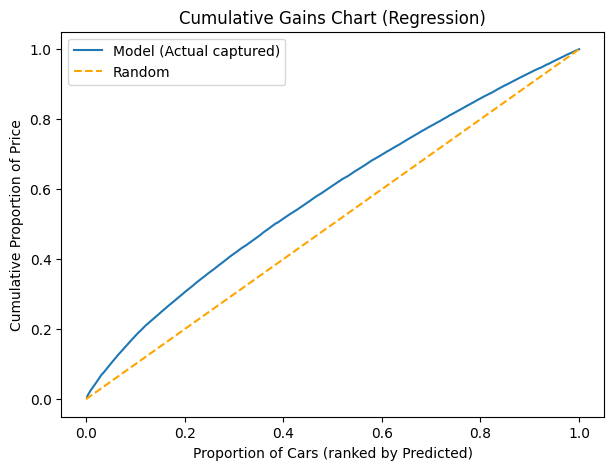

In [24]:
import numpy as np
import matplotlib.pyplot as plt


df_sorted = comparison_df.sort_values(by="Predicted", ascending=False).reset_index(drop=True)

n = len(df_sorted)

# Cumulative sums
df_sorted['cum_actual'] = df_sorted['Actual'].cumsum()
df_sorted['cum_pred']   = df_sorted['Predicted'].cumsum()

# Proportion of records for the x-axis
df_sorted['cum_pct_records'] = np.arange(1, n+1) / n

# Normalize cumulative sums to proportions (0–1 scale)
df_sorted['cum_pct_actual'] = df_sorted['cum_actual'] / df_sorted['Actual'].sum()
df_sorted['cum_pct_pred']   = df_sorted['cum_pred']   / df_sorted['Predicted'].sum()

# Plot cumulative actual proportion
plt.figure(figsize=(7,5))
plt.plot(df_sorted['cum_pct_records'], df_sorted['cum_pct_actual'],
         label='Model (Actual captured)')

# Random baseline: straight diagonal
plt.plot([0,1], [0,1], linestyle='--', color='orange', label='Random')

plt.xlabel('Proportion of Cars (ranked by Predicted)')
plt.ylabel('Cumulative Proportion of Price')
plt.title('Cumulative Gains Chart (Regression)')
plt.legend()
plt.show()

The model curve stays above the random line. The top 20% of cars (ranked by predicted price) capture more than 30% of the total price, whereas random would capture only 20%. The model does a reasonable job of ranking expensive cars higher than cheaper ones but the curve isn’t extremely steep. 

We use the cumulative gains chart because it shows how much of the total value (car prices) is captured as we move through the dataset in order of predicted values. It lets us compare the model against random selection, helping us see whether focusing on the top-ranked predictions provides a real advantage in capturing high-value cars early. We plot actual cumulative values, because the whole point of the gains chart is to measure how well predictions rank real outcomes. We do not plot predicted values, since that would only show the model’s ordering of its own guesses rather than its ability to capture the true outcomes.

To read more about the lift charts, refer to Section 5.2 of the book. 

**Lift charts are more useful in classification when we only want to target a subset. In regression (like car prices), they can still show ranking ability but are not that relevant to business needs, since every car must be priced and sold.** 

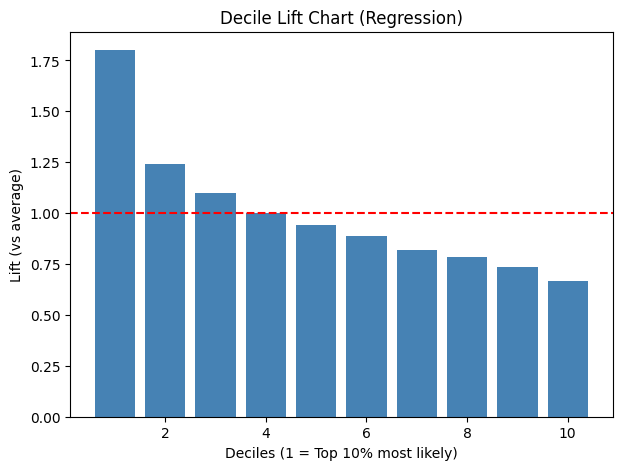

In [25]:
# Rank by predicted values
sorted_df = sorted_df.sort_values(by="Predicted", ascending=False).reset_index(drop=True)

# Assign deciles after sorting
n_deciles = 10
sorted_df['decile'] = pd.qcut(sorted_df.index, q=n_deciles, labels=False)

# Compute mean actual per decile
decile_means = sorted_df.groupby('decile')['Actual'].mean()

# Global mean
global_mean = sorted_df['Actual'].mean()

# Compute lift
decile_lift = decile_means / global_mean

# Plot corrected Decile Lift Chart
plt.figure(figsize=(7,5))
plt.bar(decile_lift.index+1, decile_lift, color='steelblue')
plt.axhline(y=1, color='red', linestyle='--')
plt.xlabel('Deciles (1 = Top 10% most likely)')
plt.ylabel('Lift (vs average)')
plt.title('Decile Lift Chart (Regression)')
plt.show()

Decile 1 has the highest lift (around 1.8). This means the cars in this decile have an average actual price almost 80% higher than the dataset average. As we move from decile 1 to decile 10, the lift steadily declines, eventually falling below 1.This shows that the bottom predicted deciles contain cars with actual prices lower than average. The model successfully identifies the most expensive cars in the top decile, and the cheapest ones end up in the bottom deciles. We use the lift chart because it shows how well the model separates high-value cases from the rest, compared to random selection.

## Classification

In [43]:
#Load the Universal Bank Dataset
ub_df = pd.read_csv("UniversalBank.csv")

#Explore the Universal Bank Dataset
print("First five rows:\n ", ub_df.head())

print(ub_df.info())

print(ub_df.describe())

First five rows:
     ID  Age  Experience  Income  ZIP Code  Family  CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4    1.6          1         0   
1   2   45          19      34     90089       3    1.5          1         0   
2   3   39          15      11     94720       1    1.0          1         0   
3   4   35           9     100     94112       1    2.7          2         0   
4   5   35           8      45     91330       4    1.0          2         0   

   Personal_Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999


In [27]:
# Split the data into train and test sets
from sklearn.model_selection import train_test_split

# randomly split ub_df into training set: 75%, and testing set: 25%
train_df, test_df = train_test_split(ub_df, test_size=0.25, random_state=42)

# print the shape of the train and test sets
print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Train set shape: (3750, 14)
Test set shape: (1250, 14)


In [28]:
# Check class distribution in the test set
class_distribution = test_df['Personal_Loan'].value_counts(normalize=True)

print("Class distribution in Test Set:")
print(class_distribution)

Class distribution in Test Set:
Personal_Loan
0    0.8928
1    0.1072
Name: proportion, dtype: float64


In [29]:
import numpy as np
from sklearn.metrics import accuracy_score

# Naive rule: predict all rejects
naive_predictions = np.zeros(len(test_df))

# Accuracy
naive_accuracy = accuracy_score(test_df['Personal_Loan'], naive_predictions)

# Misclassification error
naive_error = 1 - naive_accuracy

print(f"Naive Rule Accuracy: {naive_accuracy:.2f}")
print(f"Naive Rule Misclassification Error: {naive_error:.2f}")

Naive Rule Accuracy: 0.89
Naive Rule Misclassification Error: 0.11


Naive rule is to predicting “reject” (dominant class) for everyone, the bank is right about 89% of the time.

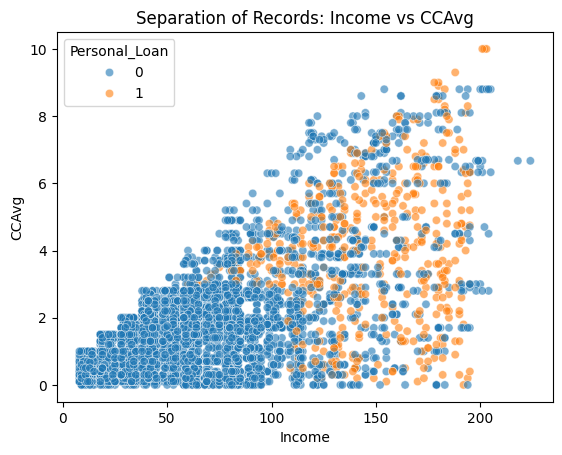

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=ub_df,
    x='Income', y='CCAvg',
    hue='Personal_Loan',
    alpha=0.6
)
plt.title("Separation of Records: Income vs CCAvg")
plt.show()

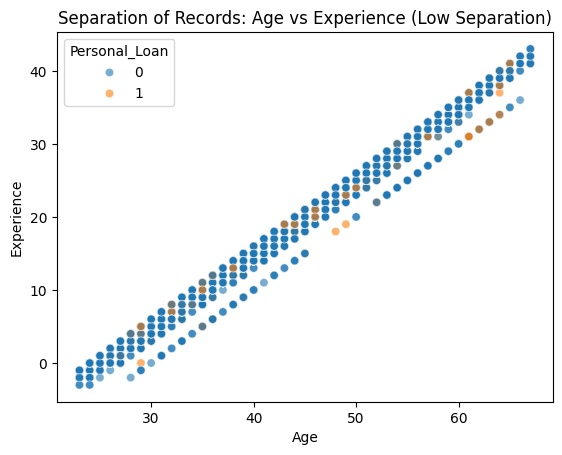

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=ub_df,
    x='Age', y='Experience',
    hue='Personal_Loan',
    alpha=0.6
)
plt.title("Separation of Records: Age vs Experience (Low Separation)")
plt.show()

In [32]:
import statsmodels.formula.api as smf

# Fit a logistic regression model
logit_model = smf.logit(
    'Personal_Loan ~ Income + CCAvg + Education + Family + Mortgage + CreditCard + Experience',
    data=train_df
)

# Fit the model
logit_model_fit = logit_model.fit()

# Print model summary
print(logit_model_fit.summary())

Optimization terminated successfully.
         Current function value: 0.144567
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:          Personal_Loan   No. Observations:                 3750
Model:                          Logit   Df Residuals:                     3742
Method:                           MLE   Df Model:                            7
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.5302
Time:                        21:00:43   Log-Likelihood:                -542.13
converged:                       True   LL-Null:                       -1154.1
Covariance Type:            nonrobust   LLR p-value:                4.845e-260
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -13.5911      0.630    -21.586      0.000     -14.825     -12.357
Income         0.0535      0.

Log likelihood: It is the function we maximize in Maximum Likelihood Estimation (MLE). The value -542.13 has no meaning as itself; rather, this number can be used to help compare nested models.

std err: These are the standard errors associated with the coefficients.  The standard error is used for testing whether the parameter is significantly different from 0. By dividing the coeffecient estimate by the standard error you obtain a z-value.

z-value: It shows how strongly each predictor is associated with the outcome. Ex: CCAvg: z = 2.558 means the coefficient is approximately 2.6 standard errors away from 0. From the p-value, the coeffecient is statistically significant. 

In [33]:
import numpy as np
import pandas as pd

# Predict probability of loan acceptance for each customer in the training set
train_df['Predicted_Prob'] = logit_model_fit.predict(train_df)

# Classify using cutoff 0.5
train_df['Predicted_Class'] = np.where(train_df['Predicted_Prob'] > 0.5, 1, 0)

# Create confusion matrix for training set
train_confusion_matrix = pd.crosstab(
    train_df['Personal_Loan'], 
    train_df['Predicted_Class'], 
    rownames=['Actual'], 
    colnames=['Predicted']
)

train_confusion_matrix

Predicted,0,1
Actual,,
0,3350,54
1,151,195


In [34]:
from sklearn.metrics import confusion_matrix

# Predict probability of loan acceptance for each customer in the training set
test_df['Predicted_Prob'] = logit_model_fit.predict(test_df)

# Classify using cutoff 0.5
test_df['Predicted_Class'] = np.where(test_df['Predicted_Prob'] > 0.5, 1, 0)

# Confusion matrix on test set
cm = confusion_matrix(test_df['Personal_Loan'], test_df['Predicted_Class'])
print("Confusion Matrix:\n", cm)

# Accuracy
accuracy = accuracy_score(test_df['Personal_Loan'], test_df['Predicted_Class'])

# Error rate (or misclassification rate)
error_rate = 1 - accuracy

print(f"Accuracy: {accuracy:.2f}")
print(f"Misclassification Rate: {error_rate:.2f}")

Confusion Matrix:
 [[1104   12]
 [  59   75]]
Accuracy: 0.94
Misclassification Rate: 0.06


In [35]:
tn = 1104
fn = 59
fp = 12
tp = 75

In [36]:
# Sensitivity (Recall for class 1, True Positive Rate)
recall = tp / (tp + fn)

# Specificity (Recall for class 0, True Negative Rate)
specificity = tn / (tn + fp)

# Precision (Positive Predictive Value)
precision = tp / (tp + fp)

# F1 Score
f1score = (2*((precision*recall)/(precision+recall)))

# False Positive Rate (1 - Specificity)
fpr = fp / (fp + tn)

# False Negative Rate (1 - Sensitivity)
fnr = fn / (fn + tp)

print(f"Sensitivity (Recall, class 1): {recall:.2f}")
print(f"Specificity (class 0): {specificity:.2f}")
print(f"Precision: {precision:.2f}")
print(f"F1 Score: {f1score:.2f}")
print(f"False Positive Rate: {fpr:.2f}")
print(f"False Negative Rate: {fnr:.2f}")

Sensitivity (Recall, class 1): 0.56
Specificity (class 0): 0.99
Precision: 0.86
F1 Score: 0.68
False Positive Rate: 0.01
False Negative Rate: 0.44


Sensitivity = 0.56: The model correctly identifies 56% of actual loan accepters.

Specificity = 0.99: The model correctly identifies 99% of actual loan rejecters.

Precision = 0.86: Of customers predicted as accepters, 86% truly accept the loan.

F1 Score = 0.68: Balance between precision and recall, showing moderate overall performance on accepters.

False Positive Rate = 0.01: Only 1% of actual rejecters are wrongly predicted as accepters.

False Negative Rate = 0.44: 44% of actual accepters are missed and predicted as rejecters.

In [37]:
from sklearn.metrics import accuracy_score

# Try different cutoff values
for cutoff in [0.3, 0.5, 0.8]:
    test_df['Predicted_Class'] = np.where(test_df['Predicted_Prob'] > cutoff, 1, 0)
    
    cm = confusion_matrix(test_df['Personal_Loan'], test_df['Predicted_Class'])
    acc = accuracy_score(test_df['Personal_Loan'], test_df['Predicted_Class'])
    
    print(f"Cutoff = {cutoff}")
    print("Confusion Matrix:")
    print(cm)
    print(f"Accuracy = {acc:.3f}\n")

Cutoff = 0.3
Confusion Matrix:
[[1080   36]
 [  34  100]]
Accuracy = 0.944

Cutoff = 0.5
Confusion Matrix:
[[1104   12]
 [  59   75]]
Accuracy = 0.943

Cutoff = 0.8
Confusion Matrix:
[[1116    0]
 [  90   44]]
Accuracy = 0.928



We try different cutoff to see how classification trade-offs (accuracy, sensitivity, specificity, errors) shift, and to choose the threshold that best fits the business objective. For example, if the bank wants to minimize false positives and don't waste money on rejectors, they can increase the threshold. 

In [38]:
# Example triage rules
test_df['Triage_Class'] = np.where(test_df['Predicted_Prob'] > 0.8, 1, 
                          np.where(test_df['Predicted_Prob'] < 0.2, 0, -1))

print(test_df['Triage_Class'].value_counts())

Triage_Class
 0    1073
-1     133
 1      44
Name: count, dtype: int64


Instead of forcing a hard cutoff at 0.5, we introduce a gray area for making better decisions. Those cases located in the gray area could be sent for further review.

In [39]:
# Calcualte the AUC for the training set
from sklearn.metrics import roc_auc_score
# Calculate the AUC for the training set
auc_train = roc_auc_score(train_df['Personal_Loan'], train_df['Predicted_Prob'])
print(f"Training AUC: {auc_train:.2f}")

Training AUC: 0.94


In [40]:
# Calculate the AUC for the test set
auc_test = roc_auc_score(test_df['Personal_Loan'], test_df['Predicted_Prob'])    
print(f"Test AUC: {auc_test:.2f}")

Test AUC: 0.95


An AUC of 0.95 on the test set and 0.94 on the training set indicates very good model performance with no overfitting.

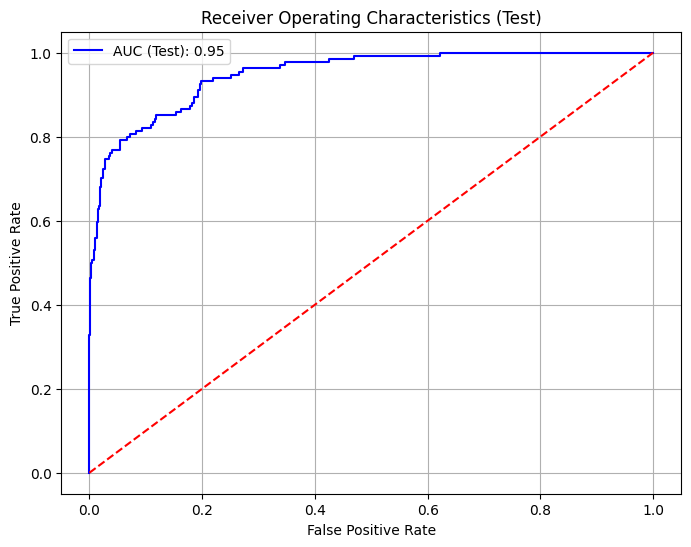

In [41]:
# Plot the ROC curve for the training set
from sklearn.metrics import roc_curve
# Calculate the ROC curve
fpr_test, tpr_test, thresholds_train = roc_curve(test_df['Personal_Loan'], test_df['Predicted_Prob'])
# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_test, tpr_test, label=f'AUC (Test): {auc_test:.2f}', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='red')  # Diagonal line
plt.title('Receiver Operating Characteristics (Test)')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')    
plt.legend()
plt.grid()  
plt.show()

The ROC curve shows that the logistic regression model is highly effective at distinguishing loan accepters from non-accepters, with AUC = 0.95. The curve shows a strong tradeoff : the model identifies most loan acceptors while keeping false positives low. The steep initial rise indicates the model performs much better than random, achieving excellent balance between sensitivity and specificity. Our optimal cutoff is at the point on the ROC curve that maximizes the tradeoff between sensitivity and specificity.

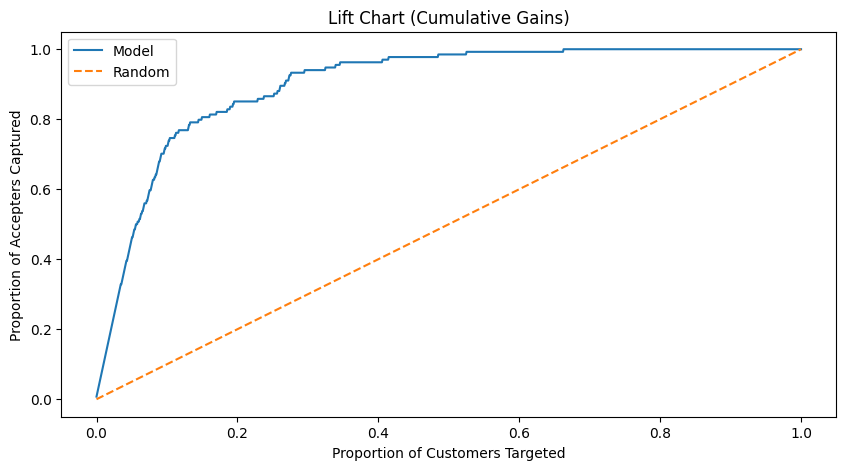

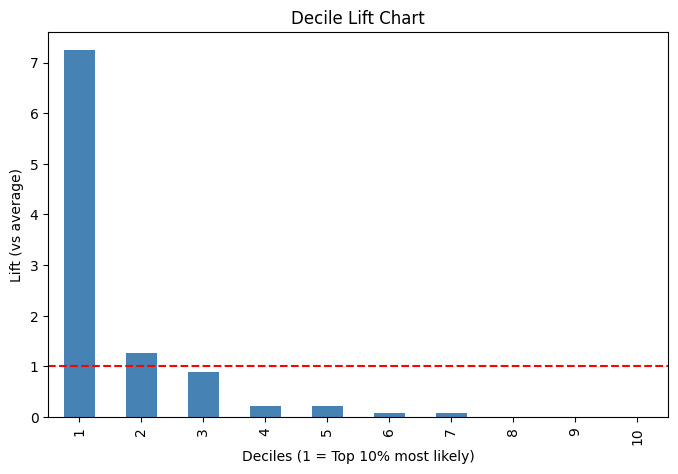

In [42]:
# Sort by predicted probability
test_df_sorted = test_df.sort_values("Predicted_Prob", ascending=False).reset_index(drop=True)

# Add deciles
test_df_sorted['Decile'] = pd.qcut(test_df_sorted.index, 10, labels=False)

# Lift Chart
cum_positives = test_df_sorted['Personal_Loan'].cumsum()
total_positives = test_df_sorted['Personal_Loan'].sum()
lift_curve = cum_positives / total_positives

# Random baseline
random_curve = np.linspace(0, 1, len(lift_curve))

plt.figure(figsize=(10,5))
plt.plot(np.linspace(0,1,len(lift_curve)), lift_curve, label="Model")
plt.plot(np.linspace(0,1,len(lift_curve)), random_curve, linestyle='--', label="Random")
plt.xlabel("Proportion of Customers Targeted")
plt.ylabel("Proportion of Accepters Captured")
plt.title("Lift Chart (Cumulative Gains)")
plt.legend()
plt.show()

# Decile lift Chart
decile_summary = test_df_sorted.groupby('Decile')['Personal_Loan'].mean()
global_mean = test_df_sorted['Personal_Loan'].mean()
decile_lift = decile_summary / global_mean

plt.figure(figsize=(8,5))

decile_lift.index = range(1, len(decile_lift)+1)

decile_lift.plot(kind='bar', color='steelblue')
plt.axhline(y=1, color='red', linestyle='--')
plt.title("Decile Lift Chart")
plt.xlabel("Deciles (1 = Top 10% most likely)")
plt.ylabel("Lift (vs average)")
plt.show()

From the CG lift chart, at 20% of customers targeted, the model captures about 80% of loan acceptors. This shows the model strongly prioritizes the most likely responders early on. At 50% of customers targeted, the model has already captured about 95% of loan acceptors, whereas random targeting would only capture 50%. 
Beyond 40–50% of customers targeted, the curve flattens because most acceptors have already been captured. This means additional targeting would bring diminishing returns, mostly likely reaching out to rejectors. The model can achieve high efficiency. For example, instead of targeting all customers, the bank can reach just 20–30% and still capture the majority of potential loan acceptors; thus, saving cost and effort.

From the decile chart, the lift is above 7, meaning the first 10% of customers (most likely acceptors according to the model) are more than 7 times as likely to accept the loan compared to random selection. The lift drops sharply after the first decile and quickly falls below the baseline. 
Deciles above 1 indicate the model is adding value; deciles below 1 mean worse than random. 